# **Boosting Algorithms: Best Algorithm + Best Parameters (Concrete Dataset)**
Target: `strength` (concrete compressive strength, MPa)

**Boosting:** trees are built one after another. Each new tree tries to fix the mistakes of the previous trees. (Bagging builds trees in parallel and averages them; boosting builds them in sequence.)

Algorithms compared:
1. **AdaBoost**
2. **Gradient Boosting**
3. **HistGradientBoosting** (fast version of Gradient Boosting, from sklearn)
4. **XGBoost**
5. **LightGBM**

Best parameters are searched with `RandomizedSearchCV` (stratified 5-fold CV). Boosting has many parameters, so random search tries many combinations faster than a full grid.

Main parameters:
- `n_estimators` / `max_iter` : number of trees
- `learning_rate` : how much each tree contributes (small = slow but safer)
- `max_depth` / `num_leaves` : size of each tree
- `subsample`, `colsample_bytree` : random part of rows / features per tree (reduces overfitting)
- `reg_lambda` / `l2_regularization` : penalty on big leaf values

### Import

In [7]:
import sys
import subprocess

try:
    import xgboost  # noqa: F401
    import lightgbm  # noqa: F401
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost", "lightgbm"])
    import xgboost
    import lightgbm


In [8]:
# In Google Colab these are already installed. Locally run:  pip install xgboost lightgbm
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


### Dataset and Stratified Split
High-strength samples are rare, so we split on strength ranges to keep the same ratio in train and test.

In [9]:
data_path = Path(r'../1. Data_Preprocessing/For_Regression/concrete_after_preprocessing.csv')
df = pd.read_csv(data_path)
x = df.drop('strength', axis=1)
y = df['strength']

#Strength ranges (used only for stratification)
bins = pd.cut(y, bins=[0, 20, 35, 50, 65, 100], labels=False)

x_train, x_test, y_train, y_test, bins_train, _ = train_test_split(
    x, y, bins, test_size=0.2, random_state=42, stratify=bins)
print(x_train.shape, x_test.shape)

#Stratified 5-fold CV (same folds for every algorithm)
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(x_train, bins_train))


(804, 8) (201, 8)


### Algorithms and Parameter Search Space
Trees do not need scaling, so there is no `StandardScaler`.

In [10]:
lr = [0.01, 0.03, 0.05, 0.1, 0.2]      # learning rates to try

models = {
    'AdaBoost': (
        AdaBoostRegressor(estimator=DecisionTreeRegressor(), random_state=42),
        {'n_estimators': [50, 100, 200, 300],
         'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
         'loss': ['linear', 'square'],
         'estimator__max_depth': [3, 5, 7, 9]}
    ),
    'GradientBoosting': (
        GradientBoostingRegressor(random_state=42),
        {'n_estimators': [100, 200, 300, 500],
         'learning_rate': lr,
         'max_depth': [2, 3, 4, 5],
         'subsample': [0.7, 0.85, 1.0],
         'min_samples_leaf': [1, 3, 5]}
    ),
    'HistGradientBoosting': (
        HistGradientBoostingRegressor(random_state=42),
        {'max_iter': [100, 200, 300, 500],
         'learning_rate': lr,
         'max_depth': [None, 3, 5, 7],
         'max_leaf_nodes': [15, 31, 63],
         'min_samples_leaf': [5, 10, 20],
         'l2_regularization': [0, 0.1, 1]}
    ),
    'XGBoost': (
        XGBRegressor(random_state=42, n_jobs=1, verbosity=0),
        {'n_estimators': [100, 200, 300, 500],
         'learning_rate': lr,
         'max_depth': [3, 4, 5, 6, 8],
         'subsample': [0.7, 0.85, 1.0],
         'colsample_bytree': [0.6, 0.8, 1.0],
         'min_child_weight': [1, 3, 5],
         'reg_lambda': [0.1, 1, 5]}
    ),
    'LightGBM': (
        LGBMRegressor(random_state=42, n_jobs=1, verbose=-1, subsample_freq=1),
        {'n_estimators': [100, 200, 300, 500],
         'learning_rate': lr,
         'num_leaves': [15, 31, 63],
         'max_depth': [-1, 5, 8],
         'subsample': [0.7, 0.85, 1.0],
         'colsample_bytree': [0.6, 0.8, 1.0],
         'min_child_samples': [5, 10, 20],
         'reg_lambda': [0, 1, 5]}
    ),
}

### RandomizedSearchCV on every algorithm
`n_iter=25` means 25 random parameter combinations are tried per algorithm (each with 5-fold CV).

In [11]:
%%time
results = []
best_models = {}

for name, (model, params) in models.items():
    t0 = time.time()
    search = RandomizedSearchCV(model, params, n_iter=25, cv=cv, scoring='r2',
                                n_jobs=-1, random_state=42, return_train_score=True)
    search.fit(x_train, y_train)

    y_pred = search.best_estimator_.predict(x_test)
    train_r2 = search.cv_results_['mean_train_score'][search.best_index_]

    results.append({
        'Model': name,
        'Train_R2': train_r2,
        'CV_R2': search.best_score_,
        'Test_R2': r2_score(y_test, y_pred),
        'Test_MAE': mean_absolute_error(y_test, y_pred),
        'Test_RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'Best_Params': search.best_params_,
    })
    best_models[name] = search.best_estimator_
    print(f"{name:<21} CV R2 = {search.best_score_:.4f} | Test R2 = {r2_score(y_test, y_pred):.4f} | {time.time()-t0:.0f}s")

AdaBoost              CV R2 = 0.8970 | Test R2 = 0.8857 | 55s
GradientBoosting      CV R2 = 0.9316 | Test R2 = 0.9119 | 23s
HistGradientBoosting  CV R2 = 0.9332 | Test R2 = 0.9158 | 37s
XGBoost               CV R2 = 0.9322 | Test R2 = 0.9188 | 74s
LightGBM              CV R2 = 0.9334 | Test R2 = 0.9102 | 13s
CPU times: total: 17.6 s
Wall time: 3min 21s


### Best Algorithm
The best algorithm is chosen by **CV R2** (the test set is not used for selection).

In [12]:
results_df = pd.DataFrame(results).sort_values('CV_R2', ascending=False).reset_index(drop=True)
display(results_df.drop(columns='Best_Params').round(4))

best = results_df.iloc[0]
best_name = best['Model']
print('===== Best Boosting Algorithm =====')
print('Model       :', best_name)
print('CV R2       :', round(best['CV_R2'], 4))
print('Test R2     :', round(best['Test_R2'], 4))
print('Test MAE    :', round(best['Test_MAE'], 4), 'MPa')
print('Test RMSE   :', round(best['Test_RMSE'], 4), 'MPa')
print('\nBest Parameters:')
for k, v in best['Best_Params'].items():
    print(f'   {k:<22}: {v}')

,Model,Train_R2,CV_R2,Test_R2,Test_MAE,Test_RMSE
0,LightGBM,0.9951,0.9334,0.9102,2.8889,4.9054
1,HistGradientBoosting,0.9908,0.9332,0.9158,2.9709,4.7491
2,XGBoost,0.9827,0.9322,0.9188,2.9353,4.6634
3,GradientBoosting,0.9883,0.9316,0.9119,2.9677,4.8575
4,AdaBoost,0.9875,0.8970,0.8857,3.5750,5.5337


===== Best Boosting Algorithm =====
Model       : LightGBM
CV R2       : 0.9334
Test R2     : 0.9102
Test MAE    : 2.8889 MPa
Test RMSE   : 4.9054 MPa

Best Parameters:
   subsample             : 0.7
   reg_lambda            : 5
   num_leaves            : 15
   n_estimators          : 500
   min_child_samples     : 10
   max_depth             : -1
   learning_rate         : 0.2
   colsample_bytree      : 1.0


### Visualization

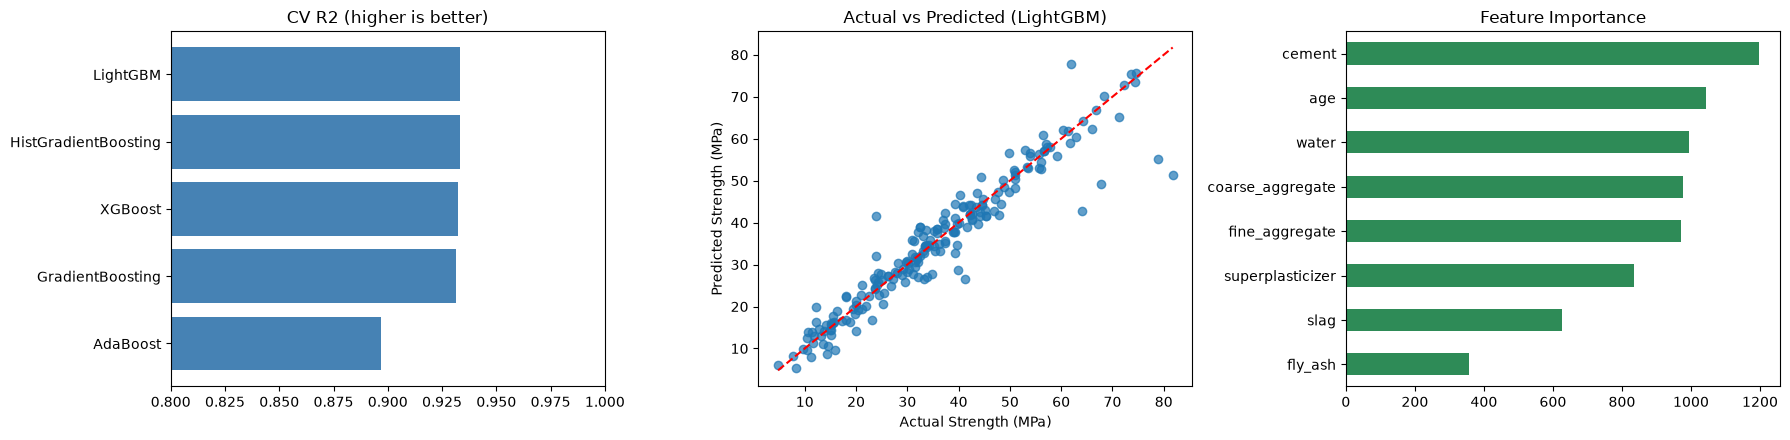

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

#CV R2 of all algorithms
ax[0].barh(results_df['Model'], results_df['CV_R2'], color='steelblue')
ax[0].invert_yaxis(); ax[0].set_xlim(0.8, 1)
ax[0].set_title('CV R2 (higher is better)')

#Actual vs Predicted (best model)
best_model = best_models[best_name]
y_pred_best = best_model.predict(x_test)
ax[1].scatter(y_test, y_pred_best, alpha=0.7)
ax[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
ax[1].set_xlabel('Actual Strength (MPa)'); ax[1].set_ylabel('Predicted Strength (MPa)')
ax[1].set_title(f'Actual vs Predicted ({best_name})')

#Feature importance (best model)
imp = pd.Series(best_model.feature_importances_, index=x.columns).sort_values()
imp.plot(kind='barh', color='seagreen', ax=ax[2])
ax[2].set_title('Feature Importance')

plt.tight_layout(); plt.show()

### Save the Best Model (.pkl)
The best algorithm (with its best parameters) is trained once more on all data, then saved with `joblib`.

In [ ]:
final_model = clone(best_model)
final_model.fit(x, y)

joblib.dump(final_model, 'boosting_best_model.pkl', compress=3)
results_df.to_csv('boosting_results.csv', index=False)
print('Saved: boosting_best_model.pkl, boosting_results.csv')

Saved: boosting_best_model.pkl, boosting_results.csv


### Load and Predict
These 5 rows were also used to train the final model, so predictions look better than reality. This cell only checks that the saved file loads and works. The honest accuracy is the **Test R2** above (trained without the test rows).

In [ ]:
model = joblib.load('boosting_best_model.pkl')

new_rows = x_test.iloc[:5]
print('Predicted strength:', model.predict(new_rows).round(2))
print('Actual strength   :', y_test.iloc[:5].round(2).values)

Predicted strength: [20.19 15.3  18.41 29.63 67.9 ]
Actual strength   : [21.97 15.07 18.03 30.23 68.3 ]


### Download (Google Colab only)

In [ ]:
try:
    from google.colab import files
    files.download('boosting_best_model.pkl')
    files.download('boosting_results.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
